In [1]:
import os
print(os.listdir('/content'))

['.config', 'GSE138260_series_matrix.txt.gz', 'sample_data']


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import gzip

In [3]:
file_path = '/content/GSE138260_series_matrix.txt.gz'

data = pd.read_csv(
    file_path,
    sep='\t',
    compression='gzip',
    comment='!'
)

In [4]:
print(data.shape)
data.head()

(947672, 37)


,ID_REF,GSM4103849,GSM4103850,GSM4103851,GSM4103852,GSM4103853,GSM4103854,GSM4103855,GSM4103856,GSM4103857,...,GSM4103875,GSM4103876,GSM4103877,GSM4103878,GSM4103879,GSM4103880,GSM4103881,GSM4103882,GSM4103883,GSM4103884
0,(+)E1A_r60_1,15.406542,14.691655,14.919350,14.964832,15.032113,14.662585,14.880789,15.287613,14.762761,...,14.465406,14.889602,14.852372,14.643821,15.135206,15.826899,14.617865,15.126639,15.111342,14.733587
1,(+)E1A_r60_3,5.387804,5.340903,5.155398,6.327329,6.069417,5.899922,5.848626,5.895226,5.656523,...,5.241246,5.591931,4.834303,5.109131,6.062218,5.785684,4.942608,5.308323,5.687478,5.163915
2,(+)E1A_r60_a104,2.131767,1.908327,1.912356,2.343290,2.666995,2.227493,1.956489,2.371638,2.585692,...,1.932877,2.191877,1.881109,1.897463,2.597896,2.309741,1.884437,2.615908,2.687115,2.174395
3,(+)E1A_r60_a107,4.147502,3.119384,2.862955,3.453019,3.729723,2.932156,3.104387,3.637705,2.920563,...,2.552861,3.982576,2.096256,2.541942,4.236055,4.054818,2.837471,3.751022,3.853696,2.851625
4,(+)E1A_r60_a135,5.841635,5.100084,5.038340,5.251436,5.851078,5.088152,5.317044,5.605756,5.206460,...,4.821372,5.826054,4.416779,4.660270,5.831730,6.047934,4.627101,5.534350,5.650433,4.869215


In [5]:
sample_info = {}

with gzip.open(file_path, 'rt') as f:
    for line in f:
        if line.startswith('!series_matrix_table_begin'):
            break

        if line.startswith('!Sample_'):
            parts = line.strip().split('\t')
            key = parts[0]
            values = [x.strip('"') for x in parts[1:]]

            sample_info[key] = values

In [6]:
metadata = pd.DataFrame({
    'GEO_ID': sample_info['!Sample_geo_accession'],
    'Sample_title': sample_info['!Sample_title']
})

In [16]:
sample_info = {}

with gzip.open(file_path, 'rt') as f:
    for line in f:
        if line.startswith('!series_matrix_table_begin'):
            break

        if line.startswith('!Sample_'):
            parts = line.rstrip('\n').split('\t')
            key = parts[0]
            values = [x.strip().strip('"') for x in parts[1:]]

            sample_info.setdefault(key, []).append(values)

In [17]:
metadata = pd.DataFrame({
    'GEO_ID': sample_info['!Sample_geo_accession'][0],
    'Sample_title': sample_info['!Sample_title'][0]
})

for row in sample_info.get('!Sample_characteristics_ch1', []):
    label = row[0].split(':', 1)[0].strip()
    values = [x.split(':', 1)[-1].strip() for x in row]

    metadata[label] = values

In [18]:
print(metadata.shape)
print(metadata.columns.tolist())
display(metadata.head())

(36, 6)
['GEO_ID', 'Sample_title', 'disease state', 'age', 'gender', 'tissue']


,GEO_ID,Sample_title,disease state,age,gender,tissue
0,GSM4103849,Brain_AD_sample1,AD,76,w,brain
1,GSM4103850,Brain_AD_sample3,AD,79,m,brain
2,GSM4103851,Brain_AD_sample4,AD,98,w,brain
3,GSM4103852,Brain_AD_sample5,AD,73,w,brain
4,GSM4103853,Brain_AD_sample6,AD,81,w,brain


In [19]:
print(metadata['disease state'].value_counts())

disease state
Control    19
AD         17
Name: count, dtype: int64


In [20]:
sample_summary = data.iloc[:, 1:].mean()

sample_summary = sample_summary.reset_index()
sample_summary.columns = ['GEO_ID', 'Mean_expression']

display(sample_summary.head())

,GEO_ID,Mean_expression
0,GSM4103849,5.190761
1,GSM4103850,5.187876
2,GSM4103851,5.190226
3,GSM4103852,5.194504
4,GSM4103853,5.189521


In [21]:
results = metadata.merge(sample_summary, on='GEO_ID')

display(results.head())

,GEO_ID,Sample_title,disease state,age,gender,tissue,Mean_expression
0,GSM4103849,Brain_AD_sample1,AD,76,w,brain,5.190761
1,GSM4103850,Brain_AD_sample3,AD,79,m,brain,5.187876
2,GSM4103851,Brain_AD_sample4,AD,98,w,brain,5.190226
3,GSM4103852,Brain_AD_sample5,AD,73,w,brain,5.194504
4,GSM4103853,Brain_AD_sample6,AD,81,w,brain,5.189521


/tmp/ipykernel_1492/2552553528.py:12: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(plot_data, labels=groups)


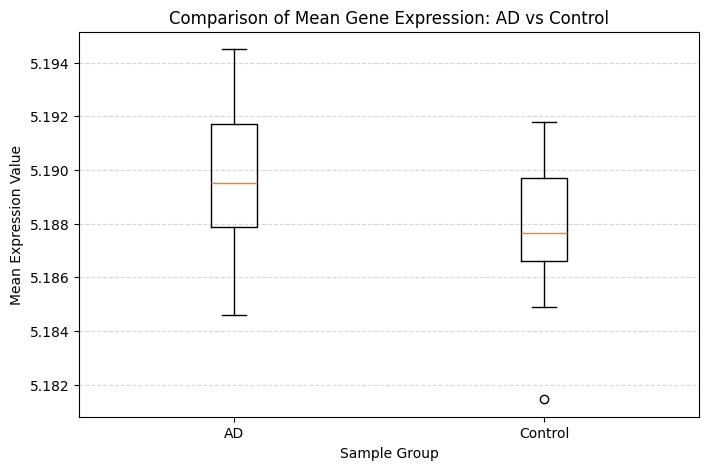

In [22]:
import matplotlib.pyplot as plt

groups = results['disease state'].unique()

plot_data = [
    results.loc[results['disease state'] == group, 'Mean_expression']
    for group in groups
]

plt.figure(figsize=(8, 5))

plt.boxplot(plot_data, labels=groups)

plt.title('Comparison of Mean Gene Expression: AD vs Control')
plt.xlabel('Sample Group')
plt.ylabel('Mean Expression Value')

plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()

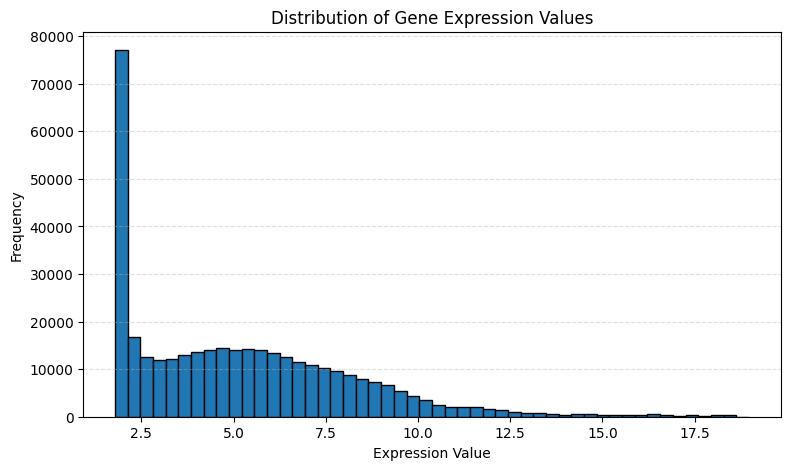

In [23]:
expression_sample = data.iloc[:, 1:].sample(
    n=10000,
    random_state=42
)

expression_values = expression_sample.to_numpy().flatten()

plt.figure(figsize=(9, 5))

plt.hist(expression_values, bins=50, edgecolor='black')

plt.title('Distribution of Gene Expression Values')
plt.xlabel('Expression Value')
plt.ylabel('Frequency')

plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.show()